In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rasaang/updated-4-dataset/Loans_Dataset.csv
/kaggle/input/datasets/rasaang/updated-4-dataset/homework 4 decision tree classfier.txt
/kaggle/input/datasets/rasaang/updated-4-dataset/homework 4 decision tree.py


Loading dataset from: /kaggle/input/datasets/rasaang/updated-4-dataset/Loans_Dataset.csv

DATA EXPLORATION & TARGET VARIABLE
Dataset Shape: 1004 rows, 6 columns
Target Variable: 'result' ('yes' = Repaid, 'No' = Default)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   initial_payment  1004 non-null   int64 
 1   last_payment     1004 non-null   int64 
 2   credit_score     1004 non-null   int64 
 3   house_number     1004 non-null   int64 
 4   sum              1004 non-null   int64 
 5   result           1004 non-null   object
dtypes: int64(5), object(1)
memory usage: 47.2+ KB

--- First 10 Rows ---
   initial_payment  last_payment  credit_score  house_number    sum result
0              201         10018           250          3046  13515    yes
1              205         10016           395          3044  13660 

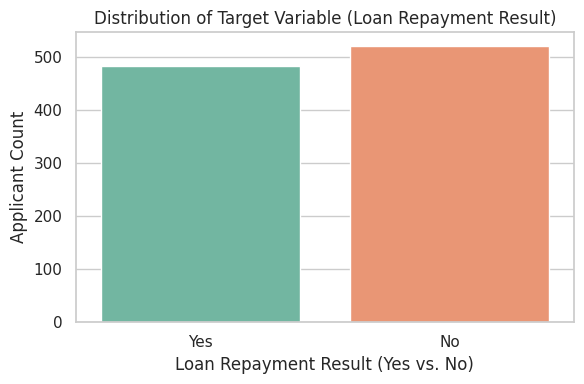

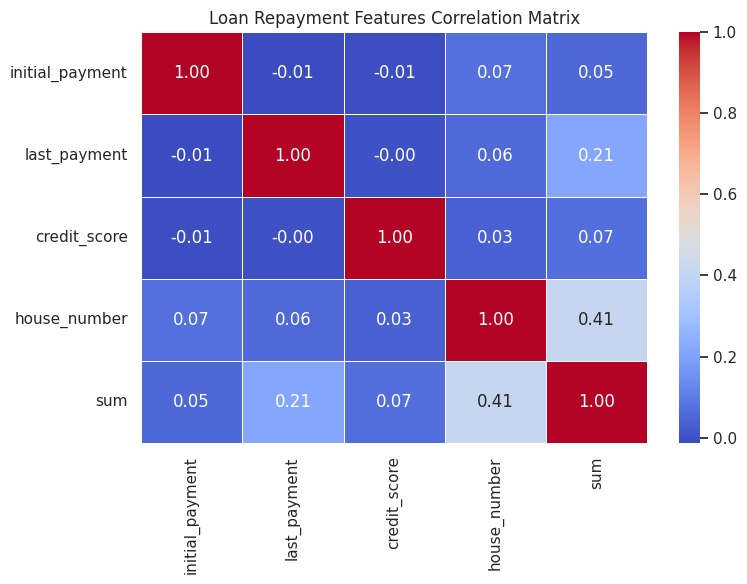

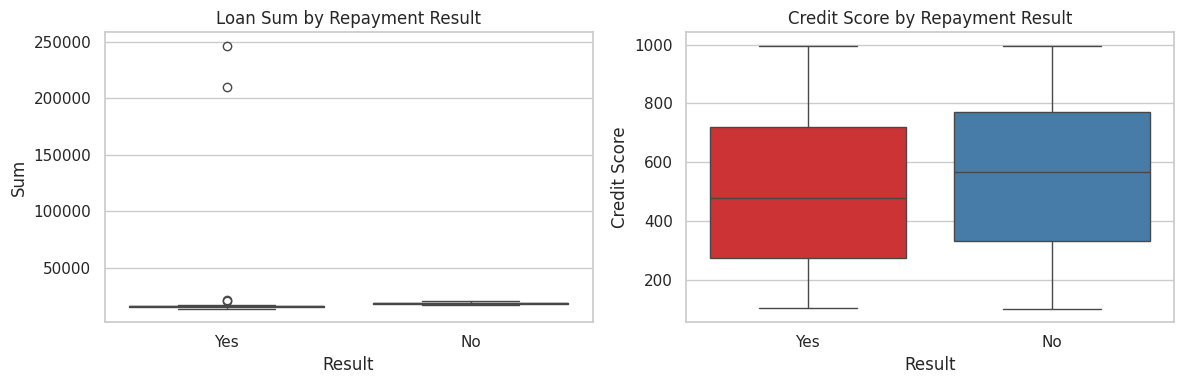


DATA PREPROCESSING & NORMALIZATION
Training Samples: 803 | Testing Samples: 201

DECISION TREE MODELING & EVALUATION
Testing Accuracy Score : 1.0000 (100.00%)
ROC-AUC Score          : 1.0000

Classification Report:
              precision    recall  f1-score   support

      No (0)       1.00      1.00      1.00       104
     Yes (1)       1.00      1.00      1.00        97

    accuracy                           1.00       201
   macro avg       1.00      1.00      1.00       201
weighted avg       1.00      1.00      1.00       201

Confusion Matrix:
[[104   0]
 [  0  97]]


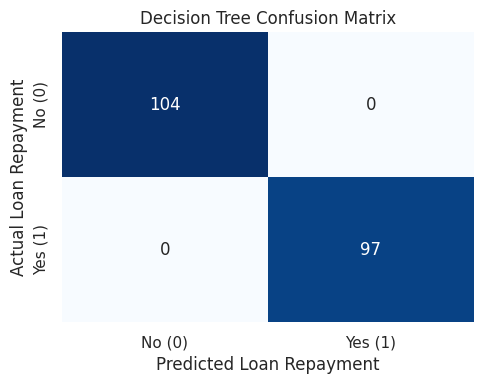

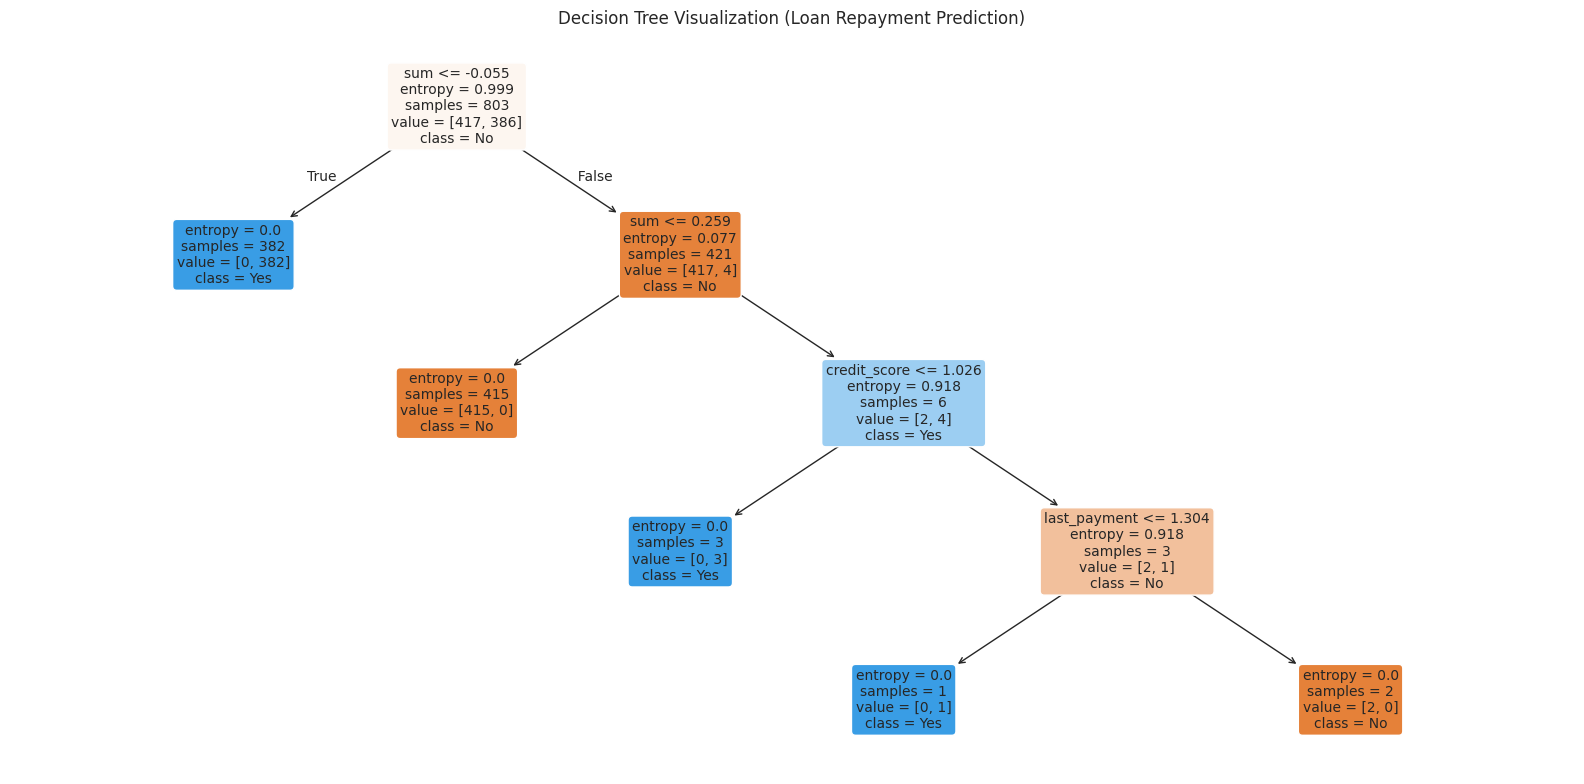

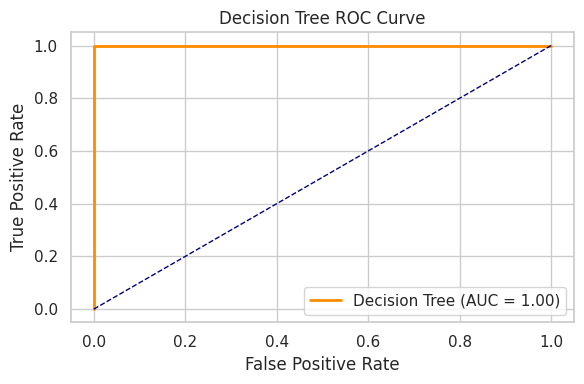

In [2]:
# Homework 4: Decision Tree Classifier (Loan Repayment Prediction)

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 500)
sns.set_theme(style="whitegrid")

# Exact path from your Kaggle Input panel
CSV_PATH = '/kaggle/input/datasets/rasaang/updated-4-dataset/Loans_Dataset.csv'
OUTPUT_DIR = '/kaggle/working'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load Dataset (with automatic fallback search just in case)
if not os.path.exists(CSV_PATH):
    for root, _, files in os.walk('/kaggle/input'):
        for f in files:
            if f == 'Loans_Dataset.csv':
                CSV_PATH = os.path.join(root, f)
                break

print(f"Loading dataset from: {CSV_PATH}")
df = pd.read_csv(CSV_PATH)
df.columns = [col.lower().strip() for col in df.columns]

# 2. Data Exploration & Target Identification
print("\n" + "=" * 60)
print("DATA EXPLORATION & TARGET VARIABLE")
print("=" * 60)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("Target Variable: 'result' ('yes' = Repaid, 'No' = Default)")
print("\n--- Dataset Info ---")
df.info()
print("\n--- First 10 Rows ---")
print(df.head(10))
print("\n--- Statistical Summary ---")
print(df.describe().round(2))

plot_df = df.copy()
plot_df['result_clean'] = plot_df['result'].astype(str).str.strip().str.capitalize()

# Exploration Chart 1: Target Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='result_clean', hue='result_clean', data=plot_df, palette='Set2', legend=False)
plt.title('Distribution of Target Variable (Loan Repayment Result)')
plt.xlabel('Loan Repayment Result (Yes vs. No)')
plt.ylabel('Applicant Count')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'hw4_target_distribution.png'), dpi=300)
plt.show()

# Exploration Chart 2: Feature Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = plot_df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Loan Repayment Features Correlation Matrix')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'hw4_correlation_heatmap.png'), dpi=300)
plt.show()

# Exploration Chart 3: Loan Sum & Credit Score by Result
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='result_clean', y='sum', hue='result_clean', data=plot_df, ax=ax1, palette='Set1', legend=False)
ax1.set_title('Loan Sum by Repayment Result')
ax1.set_xlabel('Result')
ax1.set_ylabel('Sum')

sns.boxplot(x='result_clean', y='credit_score', hue='result_clean', data=plot_df, ax=ax2, palette='Set1', legend=False)
ax2.set_title('Credit Score by Repayment Result')
ax2.set_xlabel('Result')
ax2.set_ylabel('Credit Score')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'hw4_feature_boxplots.png'), dpi=300)
plt.show()

# 3. Data Preprocessing & Normalization
print("\n" + "=" * 60)
print("DATA PREPROCESSING & NORMALIZATION")
print("=" * 60)
df_clean = df.dropna().drop_duplicates().copy()
df_clean['result'] = df_clean['result'].astype(str).str.strip().str.lower()
df_clean['target'] = df_clean['result'].map({'yes': 1, 'no': 0})

if df_clean['target'].isnull().any():
    le = LabelEncoder()
    df_clean['target'] = le.fit_transform(df_clean['result'])

feature_names = ['initial_payment', 'last_payment', 'credit_score', 'house_number', 'sum']
X = df_clean[feature_names]
y = df_clean['target'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}")

# 4. Modeling & Evaluation (Decision Tree Classifier)
print("\n" + "=" * 60)
print("DECISION TREE MODELING & EVALUATION")
print("=" * 60)
dt_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt_model.fit(X_train_scaled, y_train)

y_pred = dt_model.predict(X_test_scaled)
y_prob = dt_model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
report = classification_report(y_test, y_pred, target_names=['No (0)', 'Yes (1)'])
cm = confusion_matrix(y_test, y_pred)

print(f"Testing Accuracy Score : {acc:.4f} ({acc * 100:.2f}%)")
print(f"ROC-AUC Score          : {roc_auc:.4f}")
print("\nClassification Report:")
print(report)
print("Confusion Matrix:")
print(cm)

# Evaluation Plot 1: Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['No (0)', 'Yes (1)'], yticklabels=['No (0)', 'Yes (1)']
)
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted Loan Repayment')
plt.ylabel('Actual Loan Repayment')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'hw4_confusion_matrix.png'), dpi=300)
plt.show()

# Evaluation Plot 2: Decision Tree Structure
plt.figure(figsize=(16, 8))
plot_tree(
    dt_model,
    feature_names=feature_names,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Decision Tree Visualization (Loan Repayment Prediction)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'hw4_decision_tree_structure.png'), dpi=300)
plt.show()

# Evaluation Plot 3: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Decision Tree (AUC = {roc_auc:.2f})')
plt.plot((0, 1), (0, 1), color='navy', lw=1, linestyle='--')
plt.title('Decision Tree ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'hw4_roc_curve.png'), dpi=300)
plt.show()
